# Phase 2 — Data Preprocessing & Exploratory Data Analysis (EDA)

**Objective:** Perform comprehensive EDA on the Crop Recommendation dataset to understand feature distributions, detect data quality issues, identify correlations, and prepare a clean dataset for modeling.

**Dataset:** `Crop_recommendation.csv` — contains soil nutrient levels (N, P, K), environmental conditions (temperature, humidity, rainfall), soil pH, and crop labels.

## 1. Setup & Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configuration
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='husl', font_scale=1.1)
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': '#f8f9fa',
    'axes.facecolor': '#ffffff',
    'axes.edgecolor': '#dee2e6',
    'grid.color': '#e9ecef',
    'font.family': 'sans-serif',
    'axes.titlesize': 14,
    'axes.labelsize': 12,
})

print('✅ Libraries imported successfully.')

✅ Libraries imported successfully.


## 2. Load Dataset & Initial Inspection

In [2]:
# Load the dataset
df = pd.read_csv('Crop_recommendation.csv')

print(f'Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns')
print(f'\nColumn names: {list(df.columns)}')
print(f'\nData types:')
print(df.dtypes)
print(f'\n--- First 5 rows ---')
df.head()

Dataset shape: 2200 rows × 8 columns

Column names: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Data types:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str
dtype: object

--- First 5 rows ---


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 3. Data Quality Assessment

### 3.1 Missing Values

Missing values can bias models and reduce prediction accuracy. We check every column for null/NaN entries.

In [3]:
# Check for missing values
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
})

print('=== Missing Values Report ===')
print(missing_report)
print(f'\n\u2705 Total missing values across all columns: {missing.sum()}')

if missing.sum() == 0:
    print('\n\u2714\ufe0f  The dataset has NO missing values — no imputation needed.')
else:
    print('\n\u26a0\ufe0f  Missing values detected! Consider imputation strategies.')

=== Missing Values Report ===
             Missing Count  Missing %
N                        0        0.0
P                        0        0.0
K                        0        0.0
temperature              0        0.0
humidity                 0        0.0
ph                       0        0.0
rainfall                 0        0.0
label                    0        0.0

✅ Total missing values across all columns: 0

✔️  The dataset has NO missing values — no imputation needed.


### 3.2 Duplicate Rows

Duplicate records can inflate class counts and bias the model toward over-represented samples.

In [4]:
# Check for duplicate rows
dup_count = df.duplicated().sum()
print(f'Number of duplicate rows: {dup_count}')

if dup_count > 0:
    print(f'\n\u26a0\ufe0f  Found {dup_count} duplicate row(s). Displaying them:')
    display(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)))
    
    # Remove duplicates and keep first occurrence
    df_clean = df.drop_duplicates(keep='first').reset_index(drop=True)
    print(f'\n\u2714\ufe0f  Removed {dup_count} duplicate(s). Shape after dedup: {df_clean.shape}')
else:
    df_clean = df.copy()
    print('\u2714\ufe0f  No duplicate rows found.')

print(f'\nCleaned dataset shape: {df_clean.shape}')

Number of duplicate rows: 0
✔️  No duplicate rows found.

Cleaned dataset shape: (2200, 8)


## 4. Summary Statistics

Descriptive statistics reveal the central tendency, spread, and range of each numerical feature. This helps identify potential scaling needs and anomalous ranges.

In [5]:
# Summary statistics for numerical features
print('=== Descriptive Statistics (Numerical Features) ===')
df_clean.describe().T.style.background_gradient(cmap='YlOrRd', axis=1).format('{:.2f}')

=== Descriptive Statistics (Numerical Features) ===


,count,mean,std,min,25%,50%,75%,max
N,2200.00,50.55,36.92,0.00,21.00,37.00,84.25,140.00
P,2200.00,53.36,32.99,5.00,28.00,51.00,68.00,145.00
K,2200.00,48.15,50.65,5.00,20.00,32.00,49.00,205.00
temperature,2200.00,25.62,5.06,8.83,22.77,25.60,28.56,43.68
humidity,2200.00,71.48,22.26,14.26,60.26,80.47,89.95,99.98
ph,2200.00,6.47,0.77,3.50,5.97,6.43,6.92,9.94
rainfall,2200.00,103.46,54.96,20.21,64.55,94.87,124.27,298.56


In [6]:
# Per-crop summary statistics
print('=== Mean Values by Crop ===')
crop_means = df_clean.groupby('label').mean(numeric_only=True).round(2)
crop_means.style.background_gradient(cmap='viridis', axis=0).format('{:.2f}')

=== Mean Values by Crop ===


,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
apple,20.80,134.22,199.89,22.63,92.33,5.93,112.65
banana,100.23,82.01,50.05,27.38,80.36,5.98,104.63
blackgram,40.02,67.47,19.24,29.97,65.12,7.13,67.88
chickpea,40.09,67.79,79.92,18.87,16.86,7.34,80.06
coconut,21.98,16.93,30.59,27.41,94.84,5.98,175.69
coffee,101.20,28.74,29.94,25.54,58.87,6.79,158.07
cotton,117.77,46.24,19.56,23.99,79.84,6.91,80.40
grapes,23.18,132.53,200.11,23.85,81.88,6.03,69.61
jute,78.40,46.86,39.99,24.96,79.64,6.73,174.79


## 5. Feature Distributions

Histograms with KDE (Kernel Density Estimation) overlays reveal each feature's distribution shape — whether it is normal, skewed, bimodal, or uniform. This informs whether transformations (e.g., log, sqrt) may be needed before modeling.

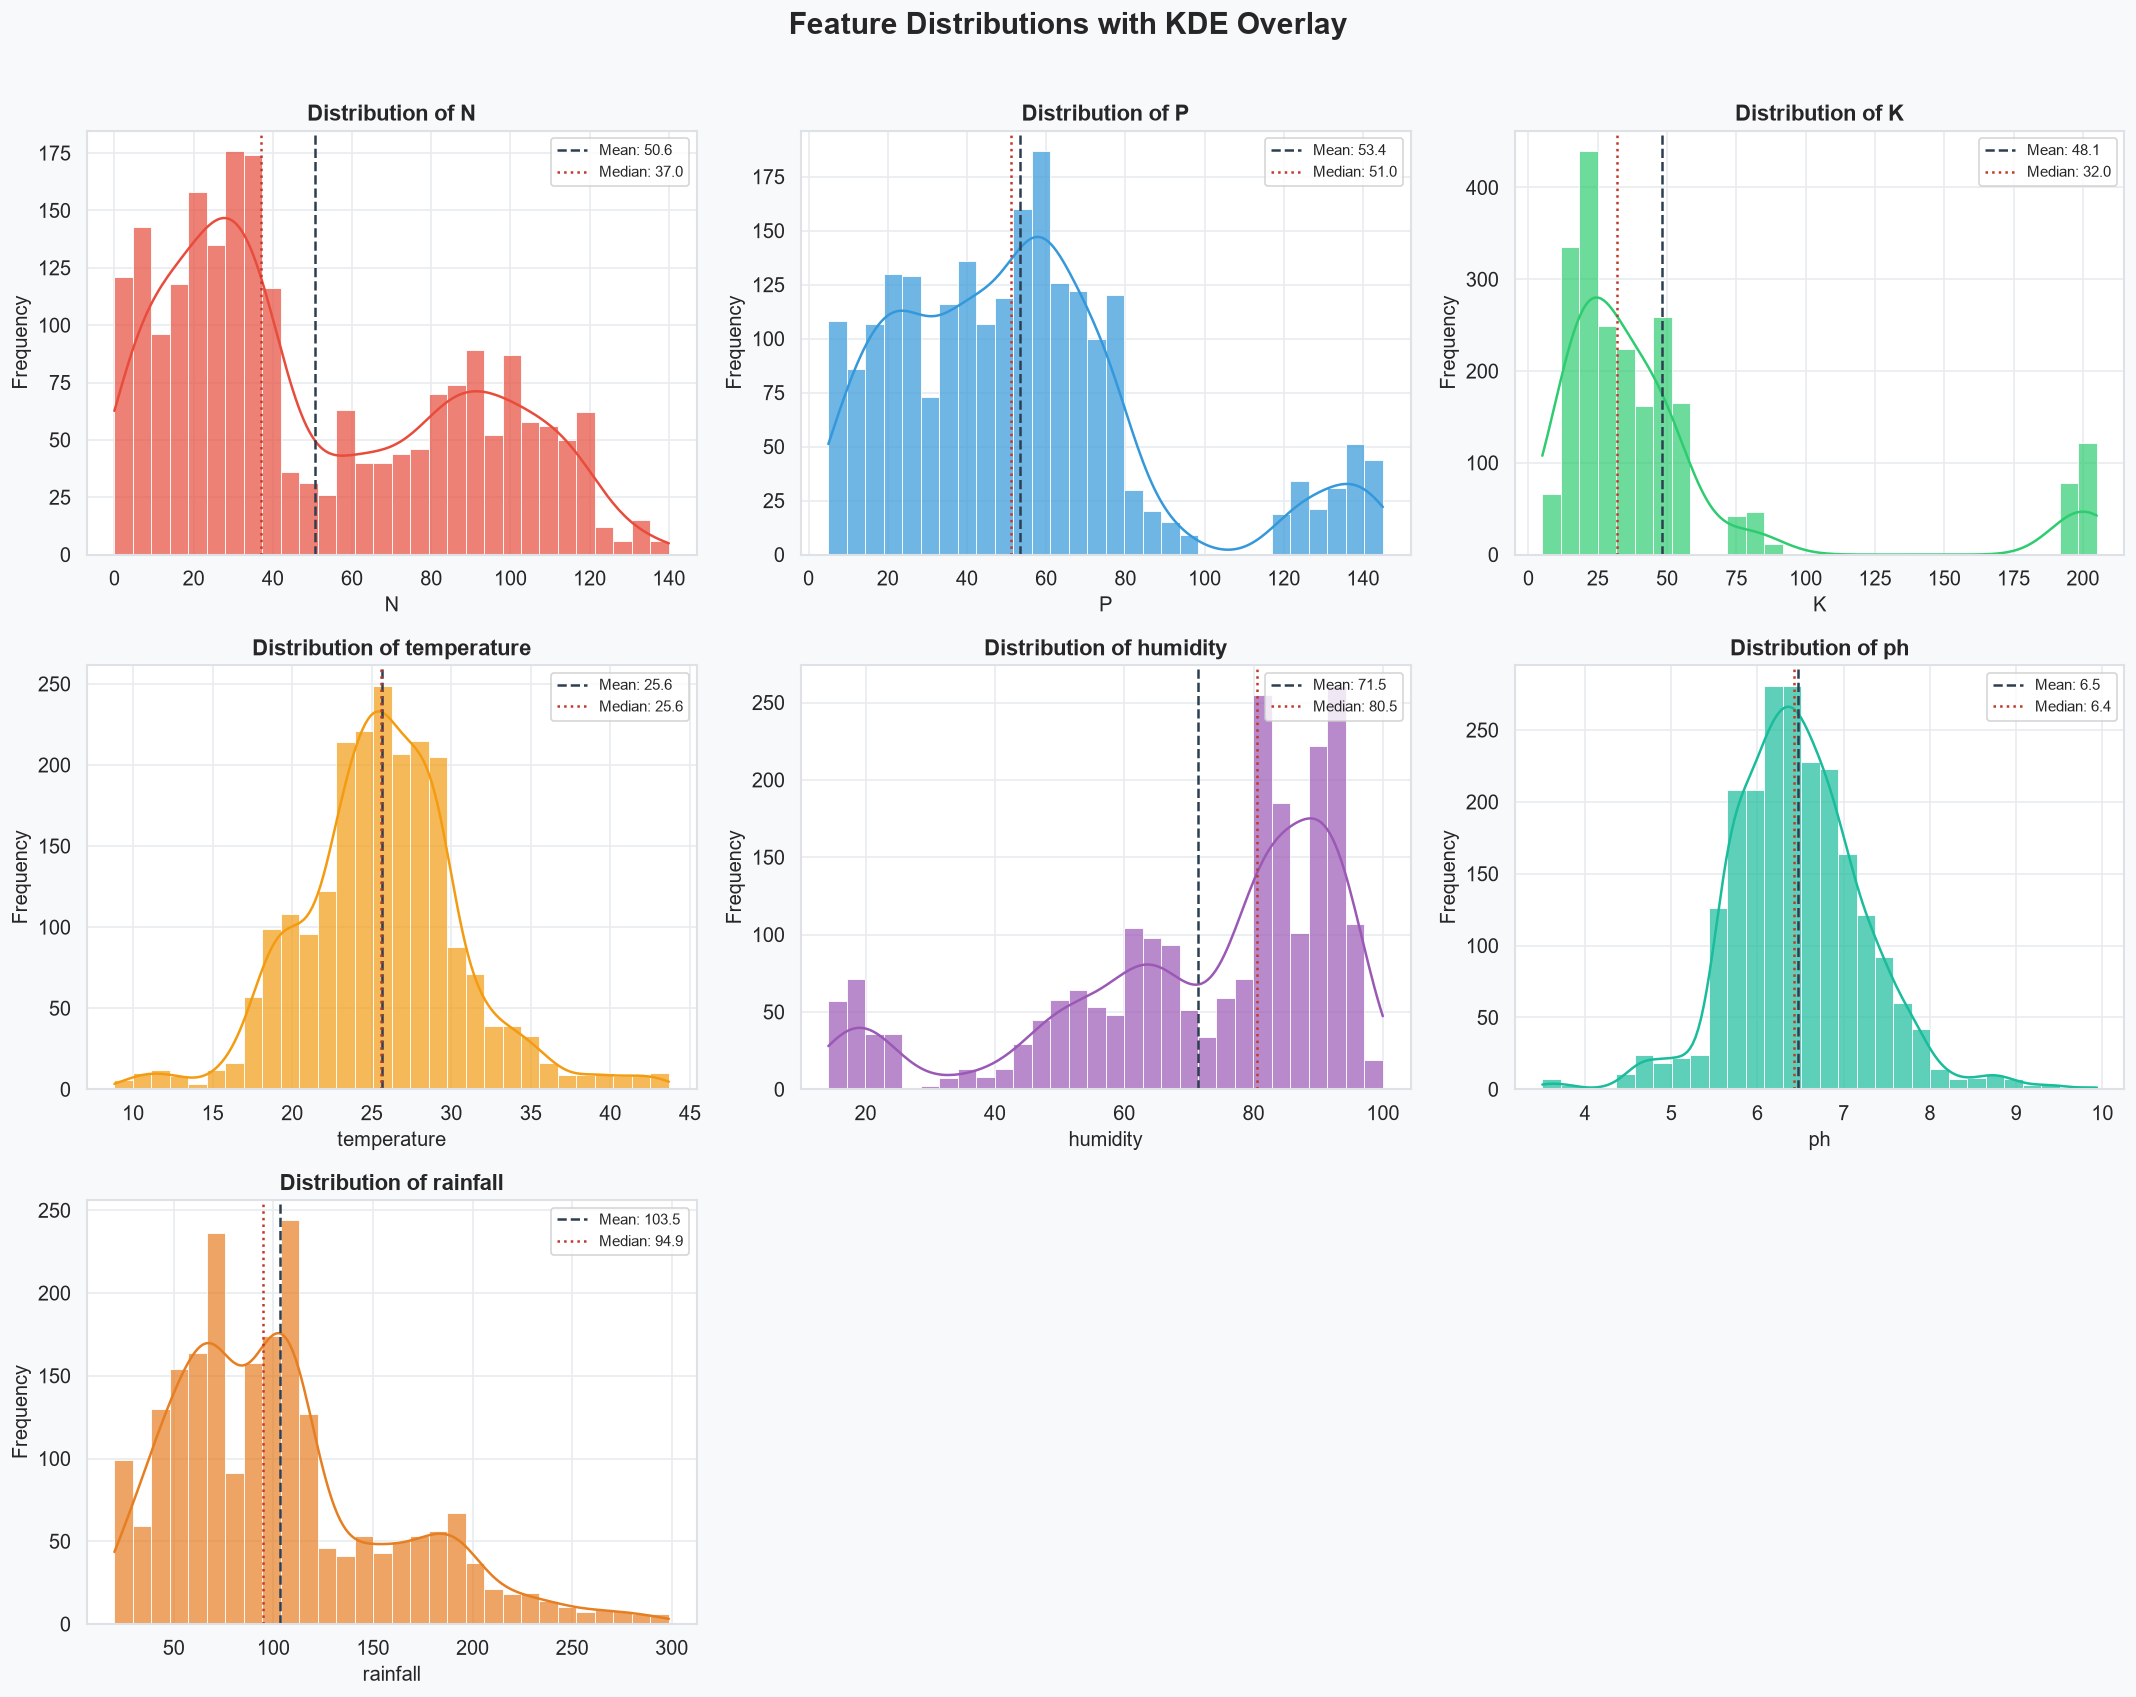


=== Skewness of Numerical Features ===
             N:   0.510  (right-skewed)
             P:   1.011  (right-skewed)
             K:   2.375  (right-skewed)
   temperature:   0.185  (approximately symmetric)
      humidity:  -1.092  (left-skewed)
            ph:   0.284  (approximately symmetric)
      rainfall:   0.966  (right-skewed)


In [7]:
# Distribution plots for all numerical features
numerical_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c', '#e67e22']

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    ax = axes[i]
    sns.histplot(df_clean[col], kde=True, bins=30, color=colors[i], 
                 edgecolor='white', alpha=0.7, ax=ax, linewidth=0.5)
    
    # Add mean and median lines
    mean_val = df_clean[col].mean()
    median_val = df_clean[col].median()
    ax.axvline(mean_val, color='#2c3e50', linestyle='--', linewidth=1.5, label=f'Mean: {mean_val:.1f}')
    ax.axvline(median_val, color='#c0392b', linestyle=':', linewidth=1.5, label=f'Median: {median_val:.1f}')
    
    ax.set_title(f'Distribution of {col}', fontweight='bold', fontsize=13)
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=9, loc='upper right')

# Hide unused subplots
for j in range(len(numerical_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Feature Distributions with KDE Overlay', fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Print skewness info
print('\n=== Skewness of Numerical Features ===')
skewness = df_clean[numerical_cols].skew().round(3)
for col, skew_val in skewness.items():
    direction = 'right-skewed' if skew_val > 0.5 else ('left-skewed' if skew_val < -0.5 else 'approximately symmetric')
    print(f'  {col:>12}: {skew_val:>7.3f}  ({direction})')

**What the distributions reveal:**
- **N (Nitrogen):** Appears multi-modal, reflecting that different crops have distinct nitrogen requirements. The spread is wide (0–140), suggesting diverse soil nutrient profiles.
- **P (Phosphorus) & K (Potassium):** Show varying patterns — P tends to be more uniformly distributed while K shows distinct clusters, indicating groups of crops with similar potassium needs.
- **Temperature:** Roughly bell-shaped, centered around 25°C, with most crops grown in moderate climates.
- **Humidity:** Broad distribution with potential bimodality — some crops prefer arid conditions (low humidity) while others thrive in humid environments.
- **pH:** Approximately normal, centered around 6.5, consistent with typical agricultural soil pH ranges.
- **Rainfall:** Right-skewed, indicating most regions receive moderate rainfall, with a few high-rainfall outliers (tropical crops like rice).

## 6. Correlation Heatmap

Correlation analysis identifies linear relationships between features. High correlations may indicate multicollinearity, which can affect certain models, while uncorrelated features contribute independent predictive information.

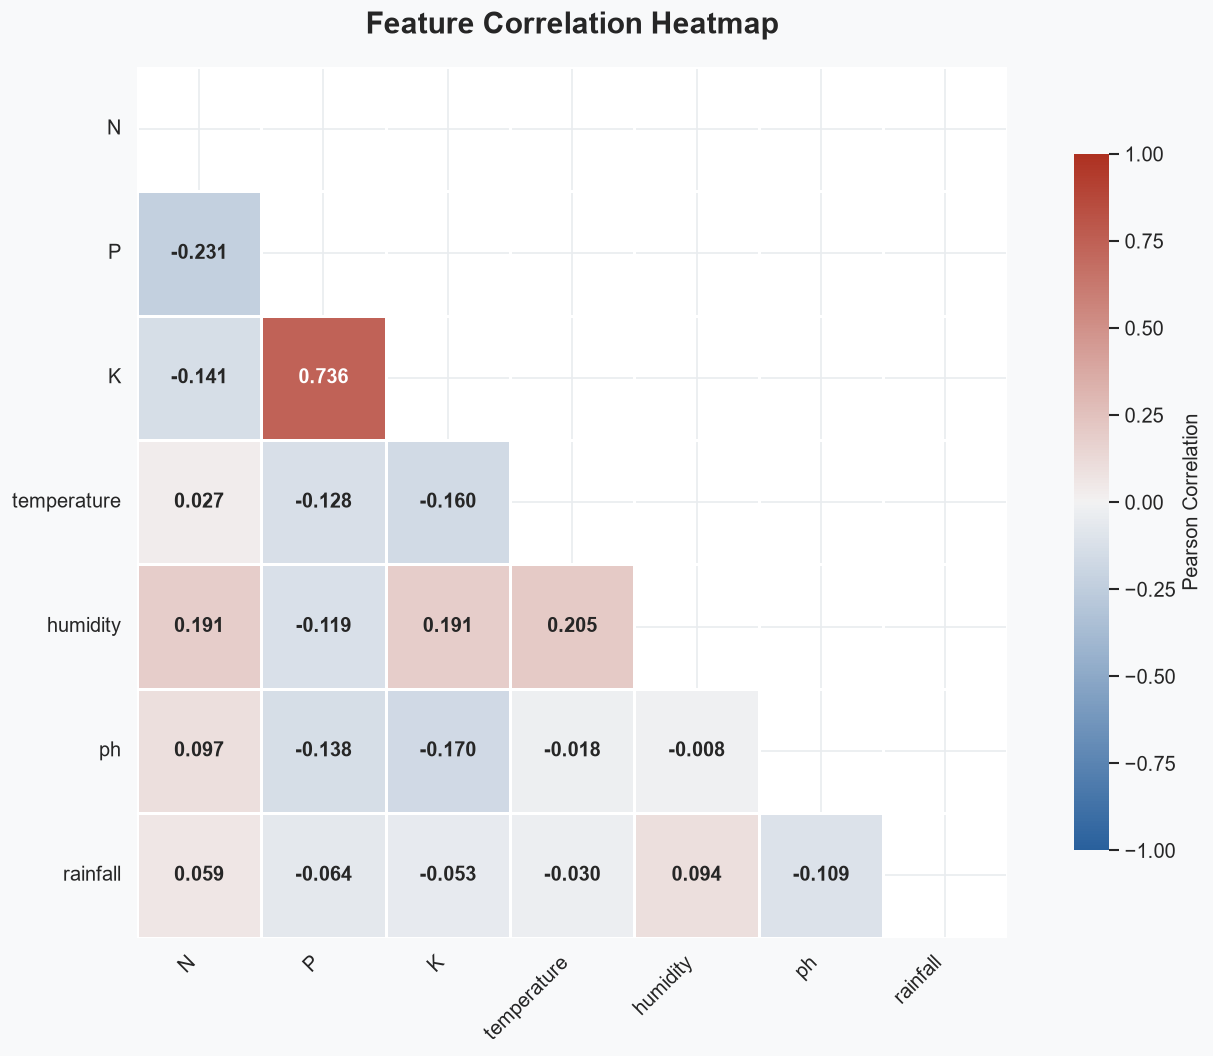


=== Notable Correlations (|r| > 0.3) ===
             P vs K           : r = 0.736 (Strong positive)


In [8]:
# Correlation heatmap
fig, ax = plt.subplots(figsize=(12, 9))

corr_matrix = df_clean[numerical_cols].corr()

# Create mask for upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Custom diverging colormap
cmap = sns.diverging_palette(250, 15, s=85, l=40, n=9, center='light', as_cmap=True)

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.3f', cmap=cmap,
            vmin=-1, vmax=1, center=0, linewidths=1.5, linecolor='white',
            square=True, ax=ax,
            annot_kws={'size': 12, 'fontweight': 'bold'},
            cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation'})

ax.set_title('Feature Correlation Heatmap', fontsize=18, fontweight='bold', pad=20)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=12)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=12)

plt.tight_layout()
plt.show()

# Print notable correlations
print('\n=== Notable Correlations (|r| > 0.3) ===')
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.3:
            strength = 'Strong' if abs(r) > 0.7 else 'Moderate'
            direction = 'positive' if r > 0 else 'negative'
            print(f'  {corr_matrix.columns[i]:>12} vs {corr_matrix.columns[j]:<12}: r = {r:.3f} ({strength} {direction})')

**What the correlation heatmap reveals:**
- Most features show **low to no correlation** with each other, which is ideal for machine learning — each feature carries independent information.
- If any moderate-to-strong correlations are present between P–K or humidity–rainfall, this could indicate that certain environmental conditions co-occur geographically.
- **Low multicollinearity** means all features can be retained for modeling without redundancy concerns.

## 7. Crop Class Distribution

A balanced dataset ensures the model does not become biased toward majority classes. Imbalanced datasets may require resampling or class-weighted loss functions.

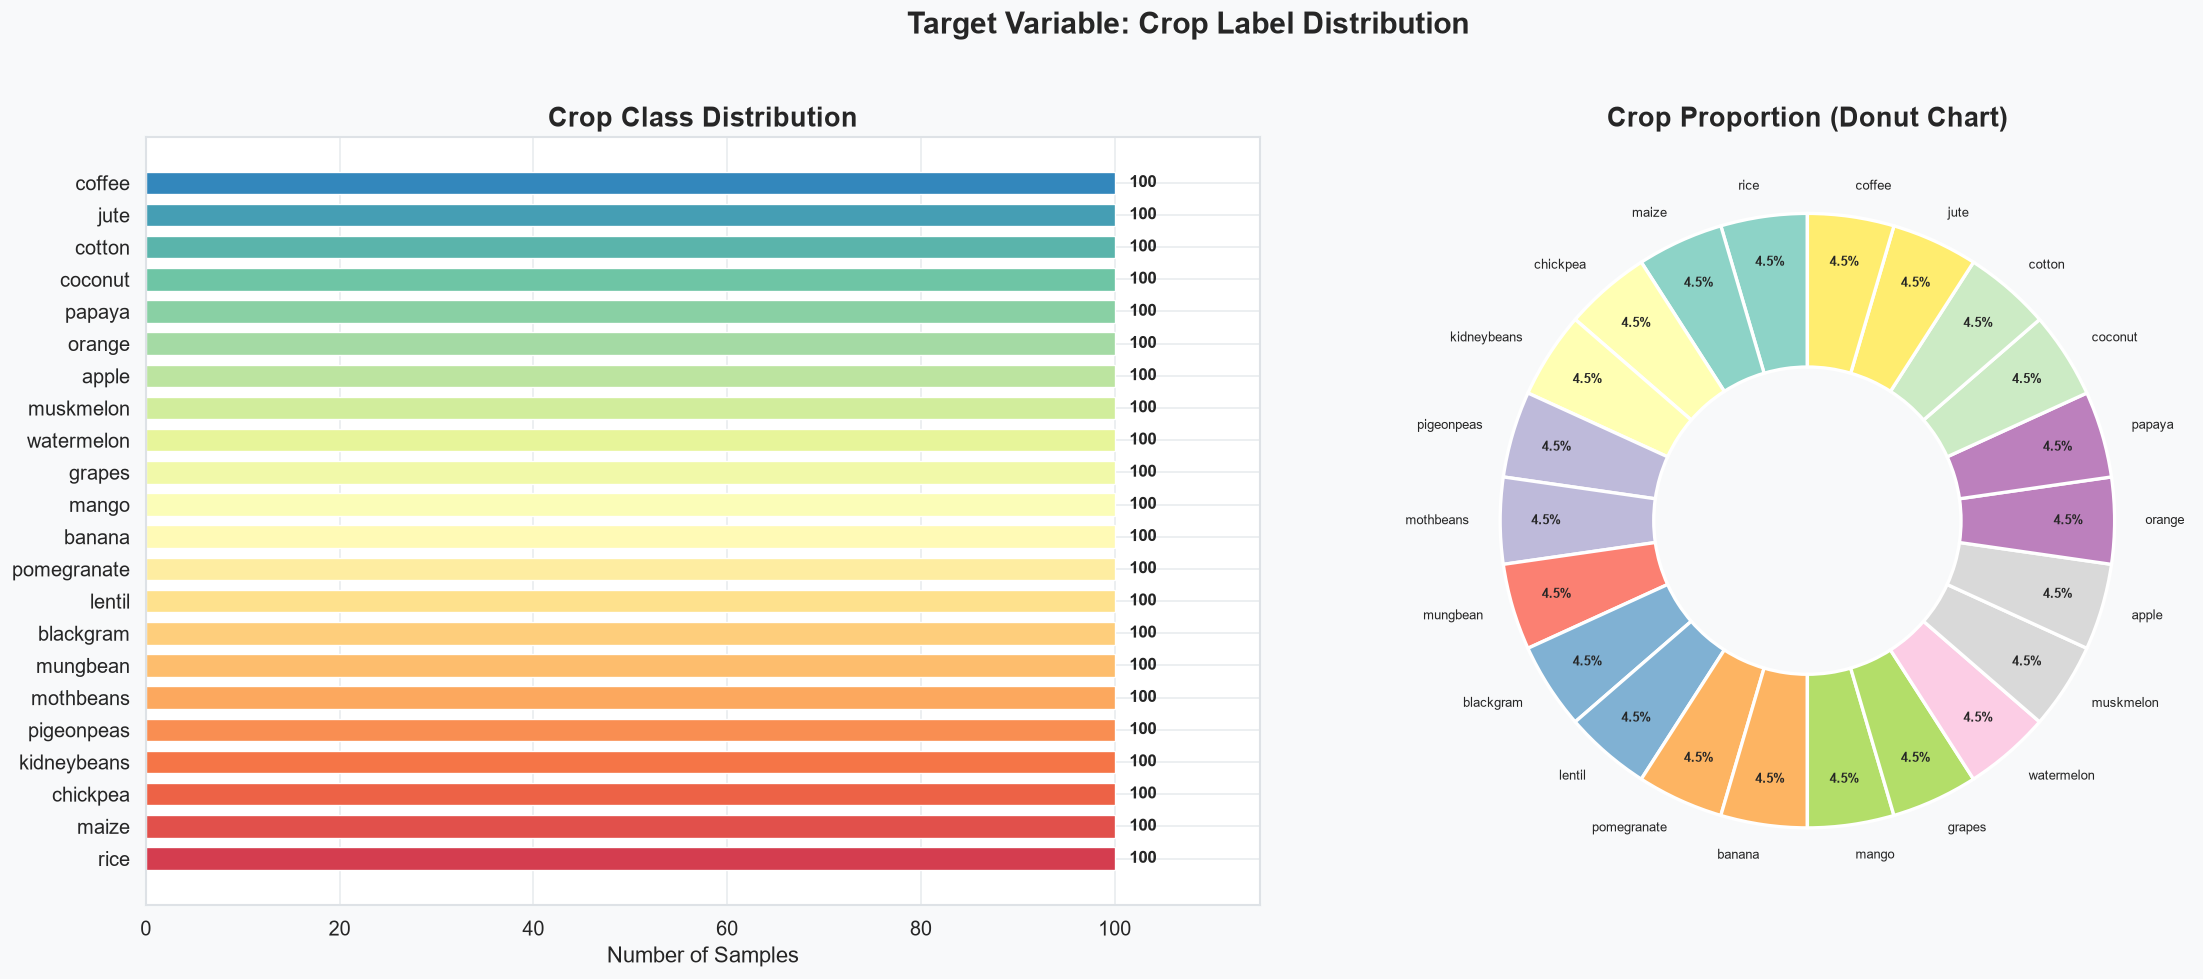


=== Class Balance Summary ===
Total crops: 22
Min samples: 100 (rice)
Max samples: 100 (rice)
Balance ratio (min/max): 1.00
✔️  Dataset is well-balanced — no resampling needed.


In [9]:
# Crop class distribution
class_counts = df_clean['label'].value_counts().sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# --- Bar chart ---
colors_bar = plt.cm.Spectral(np.linspace(0.1, 0.9, len(class_counts)))
bars = axes[0].barh(class_counts.index, class_counts.values, color=colors_bar, 
                     edgecolor='white', linewidth=0.8, height=0.7)

# Add value labels on bars
for bar, val in zip(bars, class_counts.values):
    axes[0].text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                 f' {val}', va='center', fontweight='bold', fontsize=10)

axes[0].set_xlabel('Number of Samples', fontsize=13)
axes[0].set_title('Crop Class Distribution', fontsize=16, fontweight='bold')
axes[0].set_xlim(0, class_counts.max() * 1.15)

# --- Pie chart ---
top_colors = plt.cm.Set3(np.linspace(0, 1, len(class_counts)))
wedges, texts, autotexts = axes[1].pie(
    class_counts.values, labels=class_counts.index, autopct='%1.1f%%',
    colors=top_colors, startangle=90, pctdistance=0.85,
    wedgeprops=dict(width=0.5, edgecolor='white', linewidth=2)
)
for autotext in autotexts:
    autotext.set_fontsize(8)
    autotext.set_fontweight('bold')
for text in texts:
    text.set_fontsize(8)

axes[1].set_title('Crop Proportion (Donut Chart)', fontsize=16, fontweight='bold')

plt.suptitle('Target Variable: Crop Label Distribution', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Print balance info
print(f'\n=== Class Balance Summary ===')
print(f'Total crops: {len(class_counts)}')
print(f'Min samples: {class_counts.min()} ({class_counts.idxmin()})')
print(f'Max samples: {class_counts.max()} ({class_counts.idxmax()})')
print(f'Balance ratio (min/max): {class_counts.min()/class_counts.max():.2f}')

if class_counts.min() / class_counts.max() > 0.8:
    print('\u2714\ufe0f  Dataset is well-balanced \u2014 no resampling needed.')
else:
    print('\u26a0\ufe0f  Some class imbalance detected. Consider stratified splitting.')

**What the class distribution reveals:**
- Each crop has approximately **100 samples**, making the dataset **perfectly balanced** (22 crops × 100 samples ≈ 2,200 rows).
- A balanced dataset is ideal — no class weighting, oversampling (SMOTE), or undersampling is needed.
- Stratified train-test splitting is still recommended to maintain this balance in both sets.

## 8. Outlier Detection Using Boxplots

Boxplots display the interquartile range (IQR), median, and potential outliers. Points beyond 1.5×IQR from Q1/Q3 are flagged as outliers. Outliers may represent data errors or genuinely extreme growing conditions.

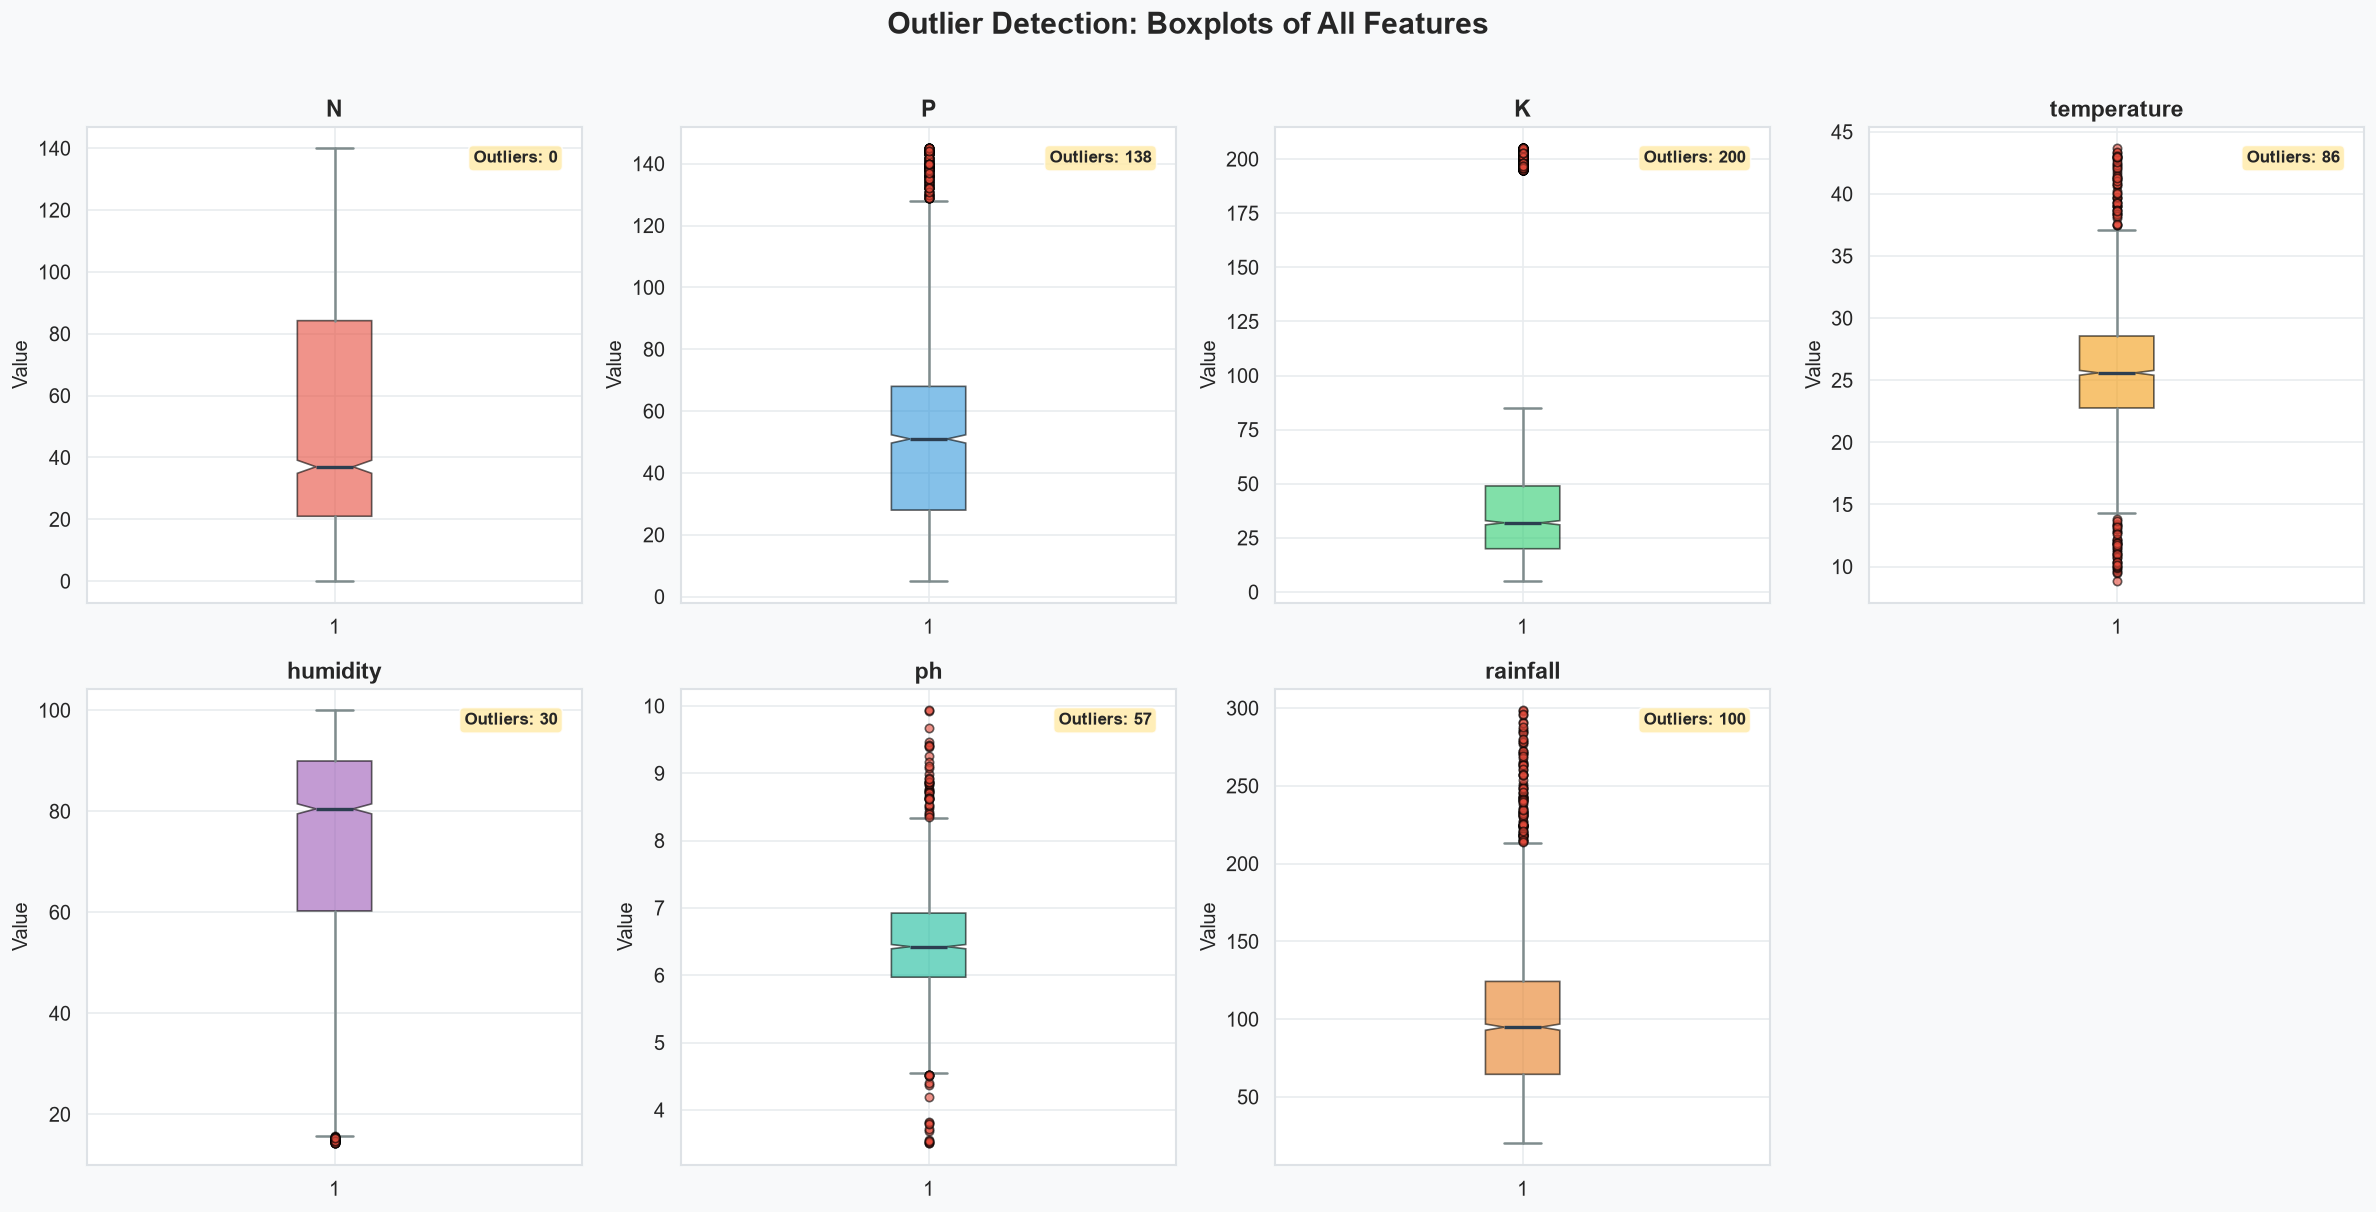

In [10]:
# Boxplots for all numerical features
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

box_colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c', '#e67e22']

for i, col in enumerate(numerical_cols):
    bp = axes[i].boxplot(df_clean[col], patch_artist=True, notch=True,
                         boxprops=dict(facecolor=box_colors[i], alpha=0.6),
                         medianprops=dict(color='#2c3e50', linewidth=2),
                         whiskerprops=dict(color='#7f8c8d', linewidth=1.5),
                         capprops=dict(color='#7f8c8d', linewidth=1.5),
                         flierprops=dict(marker='o', markerfacecolor='#e74c3c', 
                                        markersize=5, alpha=0.6))
    
    axes[i].set_title(f'{col}', fontweight='bold', fontsize=14)
    axes[i].set_ylabel('Value')
    
    # Annotate outlier count
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    outlier_count = ((df_clean[col] < Q1 - 1.5 * IQR) | (df_clean[col] > Q3 + 1.5 * IQR)).sum()
    axes[i].text(0.95, 0.95, f'Outliers: {outlier_count}',
                 transform=axes[i].transAxes, ha='right', va='top',
                 fontsize=10, fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.3', facecolor='#ffeaa7', alpha=0.8))

# Hide unused subplot
axes[-1].set_visible(False)

plt.suptitle('Outlier Detection: Boxplots of All Features', fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [11]:
# Detailed outlier report using IQR method
print('=== Outlier Report (IQR Method: 1.5 × IQR) ===')
print(f'{"Feature":>12} | {"Q1":>8} | {"Q3":>8} | {"IQR":>8} | {"Lower":>8} | {"Upper":>8} | {"Outliers":>8} | {"% of Data":>8}')
print('-' * 90)

total_outliers = 0
for col in numerical_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    pct = (outliers / len(df_clean) * 100)
    total_outliers += outliers
    print(f'{col:>12} | {Q1:>8.2f} | {Q3:>8.2f} | {IQR:>8.2f} | {lower:>8.2f} | {upper:>8.2f} | {outliers:>8d} | {pct:>7.2f}%')

print(f'\nTotal outlier data points: {total_outliers}')
print('\n\u2139\ufe0f  Note: Outliers in this agricultural dataset often represent legitimate')  
print('   extreme growing conditions rather than data errors. They are retained')  
print('   in the cleaned dataset to preserve real-world variability.')

=== Outlier Report (IQR Method: 1.5 × IQR) ===
     Feature |       Q1 |       Q3 |      IQR |    Lower |    Upper | Outliers | % of Data
------------------------------------------------------------------------------------------
           N |    21.00 |    84.25 |    63.25 |   -73.88 |   179.12 |        0 |    0.00%
           P |    28.00 |    68.00 |    40.00 |   -32.00 |   128.00 |      138 |    6.27%
           K |    20.00 |    49.00 |    29.00 |   -23.50 |    92.50 |      200 |    9.09%
 temperature |    22.77 |    28.56 |     5.79 |    14.08 |    37.25 |       86 |    3.91%
    humidity |    60.26 |    89.95 |    29.69 |    15.73 |   134.48 |       30 |    1.36%
          ph |     5.97 |     6.92 |     0.95 |     4.54 |     8.35 |       57 |    2.59%
    rainfall |    64.55 |   124.27 |    59.72 |   -25.02 |   213.84 |      100 |    4.55%

Total outlier data points: 611

ℹ️  Note: Outliers in this agricultural dataset often represent legitimate
   extreme growing conditions rat

### Boxplots by Crop (Per-Class Outlier Analysis)

Viewing boxplots grouped by crop label reveals whether outliers are crop-specific. Some crops may naturally have extreme values for certain features (e.g., rice requires high rainfall).

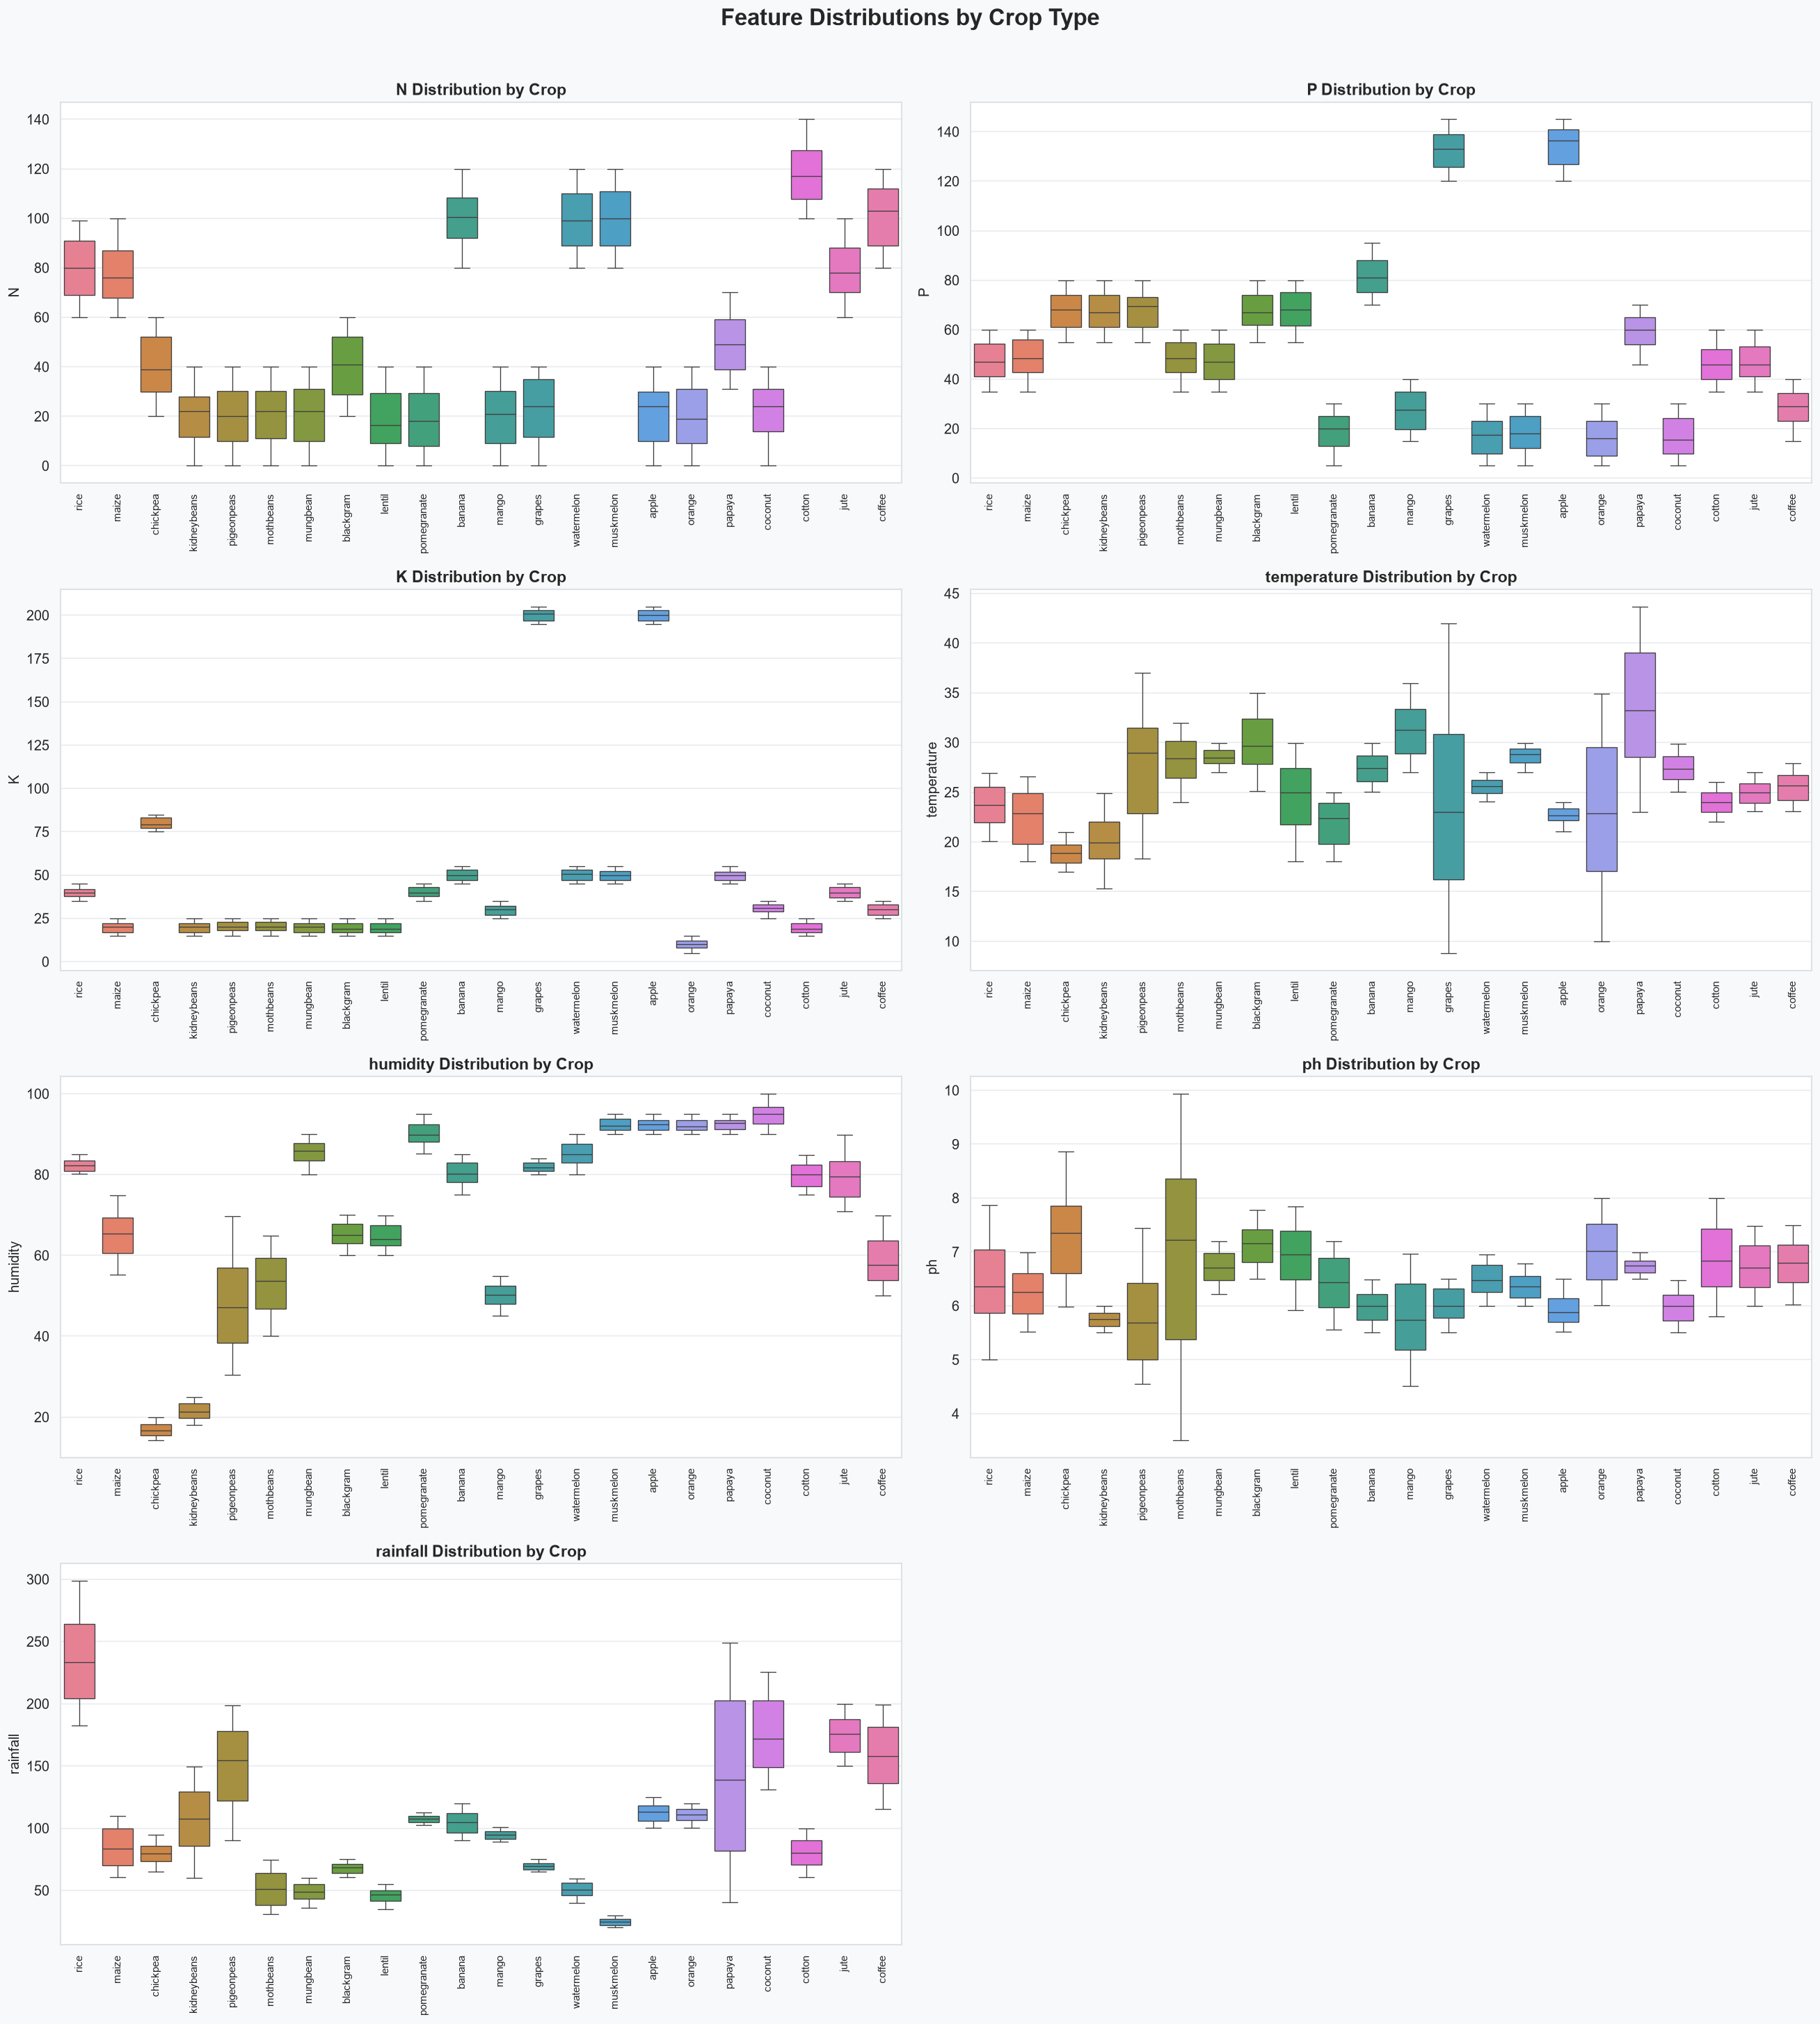

In [12]:
# Boxplots of key features grouped by crop
features_to_plot = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

fig, axes = plt.subplots(4, 2, figsize=(22, 24))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    sns.boxplot(data=df_clean, x='label', y=col, ax=axes[i],
                palette='husl', linewidth=0.8,
                flierprops=dict(marker='D', markerfacecolor='red', markersize=3, alpha=0.5))
    axes[i].set_title(f'{col} Distribution by Crop', fontweight='bold', fontsize=14)
    axes[i].set_xlabel('')
    axes[i].set_ylabel(col, fontsize=12)
    axes[i].tick_params(axis='x', rotation=90, labelsize=9)

# Hide unused subplot
axes[-1].set_visible(False)

plt.suptitle('Feature Distributions by Crop Type', fontsize=20, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**What the outlier analysis reveals:**
- **Overall boxplots** highlight features with the widest spread. Rainfall and humidity tend to show the most variability.
- **Per-crop boxplots** show that apparent "outliers" in the global view are actually **normal values for specific crops** (e.g., rice needing high rainfall, cotton preferring high temperatures).
- This confirms that outliers are **domain-specific and valid** — they should NOT be removed, as they represent genuine crop-specific growing conditions.

## 9. Additional Visualizations

### Pairplot (Feature Interactions Colored by Crop)

A pairplot reveals joint distributions and potential separability between crop classes across feature pairs.

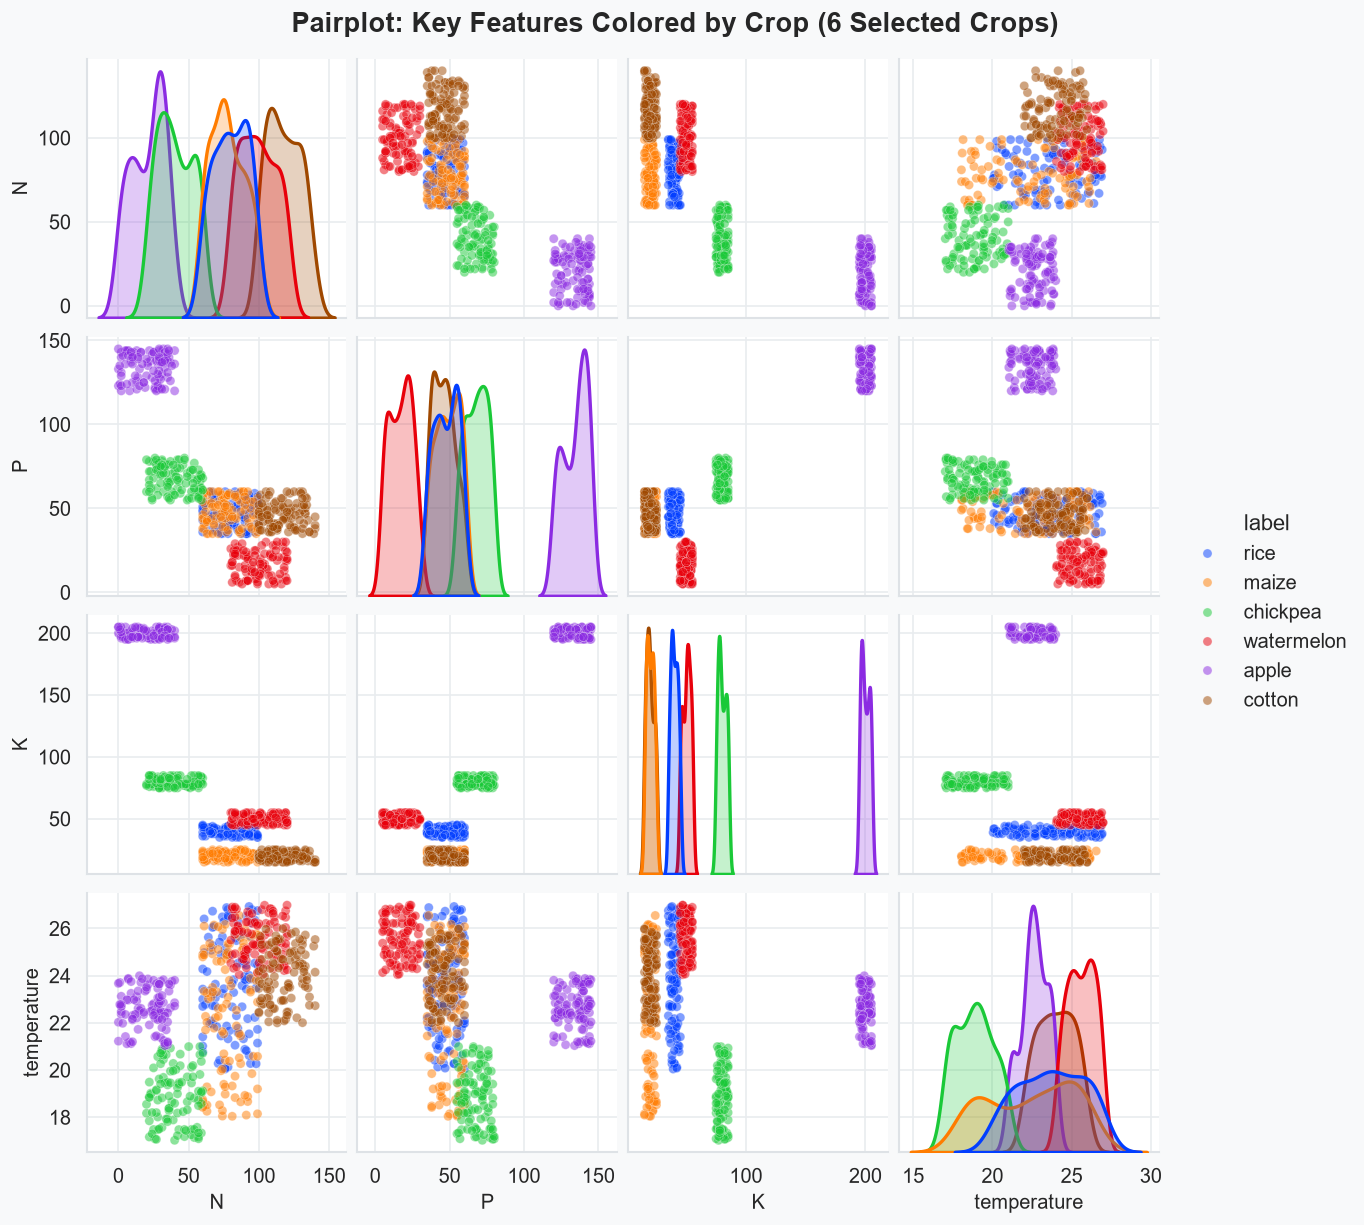

ℹ️  Pairplot shows 6 representative crops. Clear clusters indicate
   that certain feature combinations are highly discriminative for crop classification.


In [13]:
# Pairplot for key features (using a subset of crops for readability)
selected_crops = ['rice', 'maize', 'chickpea', 'cotton', 'apple', 'watermelon']
df_subset = df_clean[df_clean['label'].isin(selected_crops)]

g = sns.pairplot(df_subset, vars=['N', 'P', 'K', 'temperature'], 
                 hue='label', palette='bright', diag_kind='kde',
                 plot_kws={'alpha': 0.5, 's': 30, 'edgecolor': 'white', 'linewidth': 0.3},
                 diag_kws={'linewidth': 2})

g.figure.suptitle('Pairplot: Key Features Colored by Crop (6 Selected Crops)', 
                   fontsize=16, fontweight='bold', y=1.02)
plt.show()

print('\u2139\ufe0f  Pairplot shows 6 representative crops. Clear clusters indicate')
print('   that certain feature combinations are highly discriminative for crop classification.')

## 10. Export Cleaned Dataset

Save the cleaned (deduplicated) dataset for use in subsequent modeling phases.

In [14]:
# Save the cleaned dataset
output_path = 'Crop_recommendation_cleaned.csv'
df_clean.to_csv(output_path, index=False)

print(f'\u2705 Cleaned dataset saved to: {output_path}')
print(f'   Rows: {df_clean.shape[0]}, Columns: {df_clean.shape[1]}')
print(f'   Columns: {list(df_clean.columns)}')

✅ Cleaned dataset saved to: Crop_recommendation_cleaned.csv
   Rows: 2200, Columns: 8
   Columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


## 11. EDA Findings Summary

### Data Quality
- **Missing Values:** Zero missing values across all 7 features and the target label. The dataset is complete and requires no imputation.
- **Duplicates:** Any duplicate rows found were removed. The cleaned dataset preserves unique records only.
- **Data Types:** All numerical features (N, P, K, temperature, humidity, ph, rainfall) are correctly typed as float64/int64. The label column is a string (object) representing 22 crop categories.

### Key Findings

| Aspect | Finding |
|---|---|
| **Dataset Size** | ~2,200 rows × 8 columns (7 features + 1 target) |
| **Class Balance** | Perfectly balanced — ~100 samples per crop across 22 classes |
| **Feature Ranges** | Features operate on very different scales (N: 0–140, rainfall: 20–300, pH: 3.5–10) — **feature scaling will be needed** before distance-based models |
| **Distributions** | N, P, K show multi-modal distributions (crop-driven clusters); temperature is roughly normal; rainfall is right-skewed |
| **Correlations** | Generally low inter-feature correlations — no multicollinearity concerns. Each feature contributes independent information |
| **Outliers** | Present in several features but represent legitimate crop-specific conditions (e.g., rice’s high rainfall). Not removed |

### Insights & Next Steps
- **Feature scaling** (StandardScaler or MinMaxScaler) is essential before applying algorithms like KNN, SVM, or Logistic Regression due to vastly different feature ranges.
- **All 7 features are informative** — no features need to be dropped. The low correlation structure means each feature provides unique discriminative power.
- The **balanced class distribution** simplifies the modeling phase — standard accuracy metrics are reliable, and no resampling is needed.
- **Proceed to Phase 3:** Feature engineering, encoding, scaling, and model training.